In [1]:
%pip install torch torchvision matplotlib scipy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:

# EXPERIMENT 6: TRANSFER LEARNING USING VGG16

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

from torchvision import datasets, transforms, models
from torchvision.models import VGG16_Weights
from torch.utils.data import DataLoader, Subset
from copy import deepcopy

# 1. Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# 2. Image transformations
image_transforms = {
    'train': transforms.Compose([
        transforms.Lambda(lambda img: img.convert("RGB")),
        transforms.RandomResizedCrop(256, scale=(0.8, 1.0)),
        transforms.RandomRotation(15),
        transforms.ColorJitter(),
        transforms.RandomHorizontalFlip(),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    'valid': transforms.Compose([
        transforms.Lambda(lambda img: img.convert("RGB")),
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

# 3. Load Caltech101 dataset
train_data = datasets.Caltech101(
    root="./data", download=True, transform=image_transforms['train']
)

valid_data = datasets.Caltech101(
    root="./data", download=False, transform=image_transforms['valid']
)

n_classes = len(train_data.categories)
print("Number of classes:", n_classes)

# 4. Split dataset: 50% train, 25% validation, 25% test
total = len(train_data)
indices = torch.randperm(total).tolist()

train_end = int(0.50 * total)
valid_end = int(0.75 * total)

train_indices = indices[:train_end]
valid_indices = indices[train_end:valid_end]
test_indices = indices[valid_end:]

train_dataset = Subset(train_data, train_indices)
valid_dataset = Subset(valid_data, valid_indices)
test_dataset = Subset(valid_data, test_indices)

# 5. Create DataLoaders
batch_size = 32

trainloader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True
)

validloader = DataLoader(
    valid_dataset, batch_size=batch_size, shuffle=False
)

testloader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False
)

# 6. Load pre-trained VGG16 model
model = models.vgg16(weights=VGG16_Weights.DEFAULT)

# 7. Freeze all existing model parameters
for param in model.parameters():
    param.requires_grad = False

# 8. Replace the final classifier layer
n_inputs = model.classifier[6].in_features

model.classifier[6] = nn.Sequential(
    nn.Linear(n_inputs, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, n_classes),
    nn.LogSoftmax(dim=1)
)

model = model.to(device)

# 9. Define loss and optimizer
criterion = nn.NLLLoss()

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001
)

# 10. Train the model with early stopping
epochs = 5
patience = 2

train_losses = []
valid_losses = []
train_accs = []
valid_accs = []

best_loss = float('inf')
best_weights = deepcopy(model.state_dict())
counter = 0

for epoch in range(epochs):

    # Training
    model.train()
    running_loss = 0
    correct = 0
    total_samples = 0

    for images, labels in trainloader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()
        total_samples += labels.size(0)

    train_loss = running_loss / total_samples
    train_accuracy = correct / total_samples

    # Validation
    model.eval()
    running_loss = 0
    correct = 0
    total_samples = 0

    with torch.no_grad():
        for images, labels in validloader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total_samples += labels.size(0)

    valid_loss = running_loss / total_samples
    valid_accuracy = correct / total_samples

    train_losses.append(train_loss)
    valid_losses.append(valid_loss)
    train_accs.append(train_accuracy)
    valid_accs.append(valid_accuracy)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train Accuracy: {train_accuracy*100:.2f}% | "
        f"Validation Accuracy: {valid_accuracy*100:.2f}%"
    )

    # Early stopping
    if valid_loss < best_loss:
        best_loss = valid_loss
        best_weights = deepcopy(model.state_dict())
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping!")
            break

# Restore best model
model.load_state_dict(best_weights)

# 11. Test the model
model.eval()
correct = 0
total_samples = 0

with torch.no_grad():
    for images, labels in testloader:
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(1)

        correct += (predictions == labels).sum().item()
        total_samples += labels.size(0)

test_accuracy = correct / total_samples
print("Test Accuracy:", test_accuracy * 100, "%")

# 12. Plot performance curves
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label="Training Loss")
plt.plot(valid_losses, label="Validation Loss")
plt.title("Loss Curve")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(train_accs, label="Training Accuracy")
plt.plot(valid_accs, label="Validation Accuracy")
plt.title("Accuracy Curve")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


Using: cpu
Number of classes: 101
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to C:\Users\Harshil Bohra/.cache\torch\hub\checkpoints\vgg16-397923af.pth


100%|██████████| 528M/528M [01:46<00:00, 5.22MB/s] 


KeyboardInterrupt: 

In [ ]:

import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split

# 1. Preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# 2. Load dataset
dataset = datasets.Caltech101(
    root='./data', download=True, transform=transform
)

# 3. Split dataset: 50%, 25%, 25%
n = len(dataset)
train, valid, test = random_split(
    dataset, [int(0.5*n), int(0.25*n),
              n-int(0.75*n)]
)

trainloader = DataLoader(train, batch_size=32, shuffle=True)
testloader = DataLoader(test, batch_size=32)

# 4. Load pre-trained VGG16
model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)

# 5. Freeze weights
for param in model.parameters():
    param.requires_grad = False

# 6. Add custom classifier
n_inputs = model.classifier[6].in_features
n_classes = len(dataset.categories)

model.classifier[6] = nn.Sequential(
    nn.Linear(n_inputs, 256),
    nn.ReLU(),
    nn.Dropout(0.4),
    nn.Linear(256, n_classes),
    nn.LogSoftmax(dim=1)
)

# 7. Loss and optimizer
criterion = nn.NLLLoss()
optimizer = optim.Adam(model.classifier[6].parameters(), lr=0.001)

# 8. Train model
epochs = 5
losses = []

for epoch in range(epochs):
    model.train()
    total_loss = 0

    for images, labels in trainloader:
        optimizer.zero_grad()
        output = model(images)
        loss = criterion(output, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    losses.append(total_loss / len(trainloader))
    print("Epoch:", epoch+1, "Loss:", losses[-1])

# 9. Calculate test accuracy
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        output = model(images)
        predictions = output.argmax(1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

print("Test Accuracy:", 100 * correct / total, "%")

# 10. Plot loss
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()


Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 17s 102ms/step - accuracy: 0.6538 - loss: 1.0604 - val_accuracy: 0.7880 - val_loss: 0.6628
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - accuracy: 0.8330 - loss: 0.4943 - val_accuracy: 0.8170 - val_loss: 0.5625
Epoch 3/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 97ms/step - accuracy: 0.8788 - loss: 0.3726 - val_accuracy: 0.8180 - val_loss: 0.5565
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.8160 - loss: 0.5151
Test Accuracy: 81.5999984741211 %


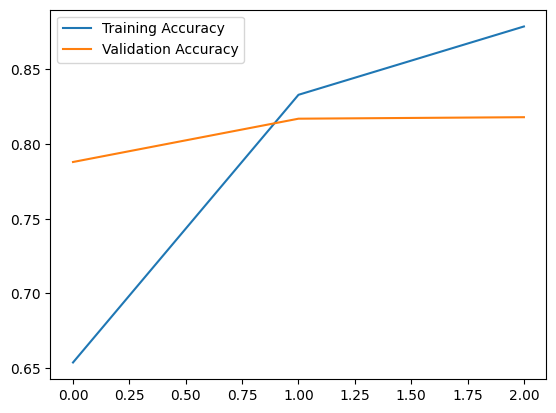

In [5]:

import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

# 1. Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

x_train = tf.image.resize(x_train[:5000], (96, 96))
x_test = tf.image.resize(x_test[:1000], (96, 96))

y_train = y_train[:5000]
y_test = y_test[:1000]

# 2. Preprocess images
x_train = keras.applications.mobilenet_v2.preprocess_input(x_train)
x_test = keras.applications.mobilenet_v2.preprocess_input(x_test)

# 3. Load pre-trained MobileNetV2
base_model = keras.applications.MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(96, 96, 3)
)

# 4. Freeze pre-trained layers
base_model.trainable = False

# 5. Add custom classifier
model = keras.Sequential([
    base_model,
    keras.layers.GlobalAveragePooling2D(),
    keras.layers.Dense(10, activation='softmax')
])

# 6. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 7. Train model
history = model.fit(
    x_train, y_train,
    epochs=3,
    batch_size=32,
    validation_split=0.2
)

# 8. Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy * 100, "%")

# 9. Plot accuracy
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.show()


(60000, 28, 28)
(10000, 28, 28)
Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.8351 - loss: 0.6447
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9041 - loss: 0.3428
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9155 - loss: 0.2971
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9240 - loss: 0.2676
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.9312 - loss: 0.2451
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9345 - loss: 0.2302
Test Accuracy: 0.934499979019165


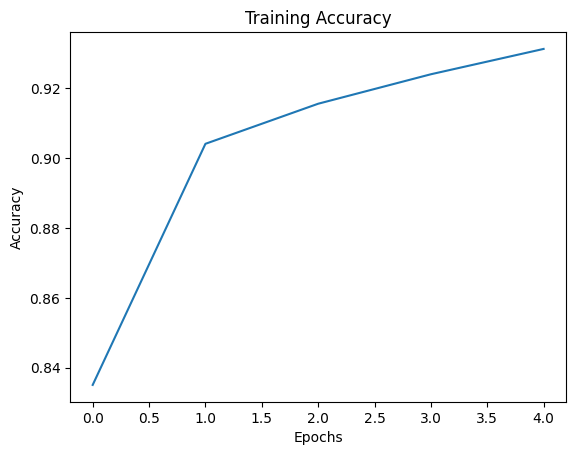

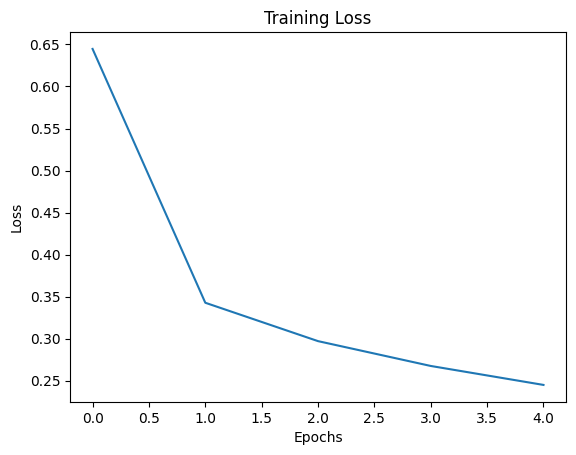

In [6]:

import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

# 1. Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print(x_train.shape)
print(x_test.shape)

# 2. Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0

# 3. Create Feedforward Neural Network
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

# 4. Compile model
model.compile(
    optimizer='sgd',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Train model
history = model.fit(x_train, y_train, epochs=5)

# 6. Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy)

# 7. Plot accuracy
plt.plot(history.history['accuracy'])
plt.title('Training Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

# 8. Plot loss
plt.plot(history.history['loss'])
plt.title('Training Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.show()


Epoch 1/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 15s 9ms/step - accuracy: 0.4536 - loss: 1.5158 - val_accuracy: 0.5488 - val_loss: 1.2464
Epoch 2/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.5935 - loss: 1.1524 - val_accuracy: 0.6152 - val_loss: 1.1013
Epoch 3/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.6431 - loss: 1.0261 - val_accuracy: 0.6498 - val_loss: 1.0174
Epoch 4/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - accuracy: 0.6709 - loss: 0.9467 - val_accuracy: 0.6664 - val_loss: 0.9527
Epoch 5/5
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - accuracy: 0.6938 - loss: 0.8825 - val_accuracy: 0.6924 - val_loss: 0.9048
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6854 - loss: 0.9272
Test Accuracy: 0.6854000091552734


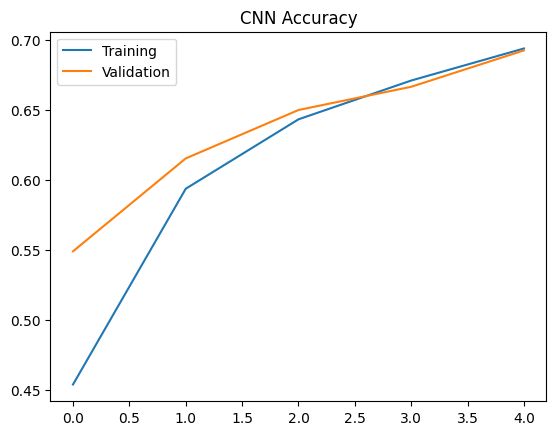

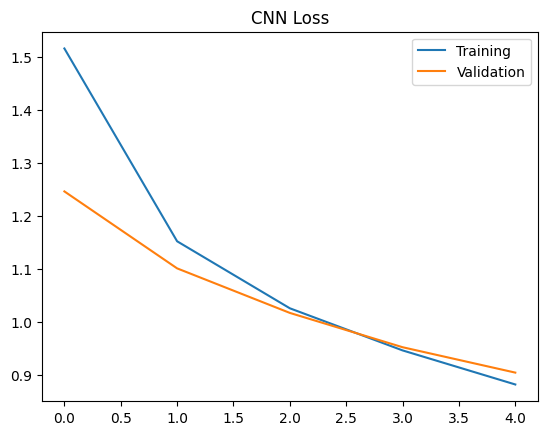

In [7]:

import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt

# 1. Load CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

# 2. Normalize images
x_train = x_train / 255.0
x_test = x_test / 255.0

# 3. Create CNN model
model = keras.Sequential([
    keras.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(32, (3,3), activation='relu'),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Conv2D(64, (3,3), activation='relu'),
    keras.layers.MaxPooling2D((2,2)),
    keras.layers.Flatten(),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(10, activation='softmax')
])

# 4. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Train model
history = model.fit(
    x_train, y_train,
    epochs=5,
    validation_split=0.1
)

# 6. Evaluate model
loss, accuracy = model.evaluate(x_test, y_test)
print("Test Accuracy:", accuracy)

# 7. Plot accuracy
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('CNN Accuracy')
plt.legend()
plt.show()

# 8. Plot loss
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('CNN Loss')
plt.legend()
plt.show()


Epoch 1/5


C:\Users\Harshil Bohra\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


47/47 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1209
Epoch 2/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0536
Epoch 3/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0420
Epoch 4/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0361
Epoch 5/5
47/47 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0322
31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
282/282 ━━━━━━━━━━━━━━━━━━━━ 0s 924us/step
Threshold: 0.04234085855563523
Normal Error: 0.0305380538989189
Anomaly Error: 0.081055037947143
Anomaly Detected: True


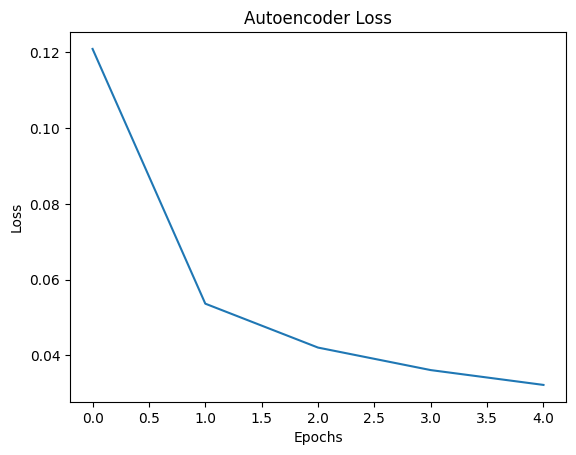

In [8]:

import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt

# 1. Load MNIST dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

# 2. Normalize data
x_train = x_train / 255.0
x_test = x_test / 255.0

# 3. Select normal data (digit 0)
x_train = x_train[y_train == 0]
x_test_normal = x_test[y_test == 0]
x_test_anomaly = x_test[y_test != 0]

# 4. Create Autoencoder
model = keras.Sequential([
    keras.layers.Flatten(input_shape=(28, 28)),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(32, activation='relu'),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dense(784, activation='sigmoid'),
    keras.layers.Reshape((28, 28))
])

# 5. Compile model
model.compile(optimizer='adam', loss='mse')

# 6. Train using normal images only
history = model.fit(
    x_train, x_train,
    epochs=5,
    batch_size=128
)

# 7. Calculate reconstruction errors
normal_pred = model.predict(x_test_normal)
anomaly_pred = model.predict(x_test_anomaly)

normal_error = np.mean((x_test_normal - normal_pred)**2, axis=(1,2))
anomaly_error = np.mean((x_test_anomaly - anomaly_pred)**2, axis=(1,2))

# 8. Set threshold
threshold = np.mean(normal_error) + np.std(normal_error)
print("Threshold:", threshold)

# 9. Detect anomalies
print("Normal Error:", np.mean(normal_error))
print("Anomaly Error:", np.mean(anomaly_error))

print("Anomaly Detected:",
      np.mean(anomaly_error) > threshold)

# 10. Plot training loss
plt.plot(history.history['loss'])
plt.title("Autoencoder Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()


In [9]:

import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Lambda, Dense

# 1. Input text
text = "I love deep learning and artificial intelligence"

words = text.lower().split()
vocab = sorted(set(words))

word_to_id = {w:i for i,w in enumerate(vocab)}
id_to_word = {i:w for w,i in word_to_id.items()}

# 2. Generate context and target words
X, Y = [], []

for i in range(1, len(words)-1):
    X.append([word_to_id[words[i-1]],
              word_to_id[words[i+1]]])
    Y.append(word_to_id[words[i]])

X = np.array(X)
Y = np.array(Y)

# 3. Create CBOW model
model = Sequential([
    Embedding(len(vocab), 10),
    Lambda(lambda x: tf.reduce_mean(x, axis=1)),
    Dense(len(vocab), activation='softmax')
])

# 4. Compile model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 5. Train model
model.fit(X, Y, epochs=100, verbose=0)

# 6. Predict target word
prediction = model.predict(X[:1], verbose=0)
word_id = np.argmax(prediction)

print("Predicted word:", id_to_word[word_id])



Predicted word: love
